# RQ05 — frequência de deploy × taxa de falha (Issue #66)

Correlação de Spearman entre a frequência de *deploy* (RQ01, `deploy_freq_release`) e o CFR (RQ03), separadamente para a variante (a), *proxy* de CI, e (b), *proxy* de entrega. Spearman usa só a ordem dos valores: não exige normalidade nem relação linear. Correlação não implica causalidade.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter
from scipy.stats import spearmanr

ANALISE = Path.cwd()
CODE = ANALISE.parent / 'code'
sys.path.insert(0, str(CODE))
from metrics.estatistica import ic_spearman

FIGURAS = ANALISE / 'figuras'
TABELAS = ANALISE / 'tabelas'
FIGURAS.mkdir(exist_ok=True)
TABELAS.mkdir(exist_ok=True)

df = pd.read_csv(CODE / 'data' / 'dataset_dora.csv')
print(f'{len(df)} repositórios')

300 repositórios


## Correlações

As duas variantes obrigatórias vêm primeiro. A terceira linha é um controle para o CFR (b): troca a taxa de falha pela *rework rate* (RQ08), a proporção de *releases* corretivas, que usa a mesma heurística mas não depende do prazo de 7 dias depois de cada *release*. Se a correlação do CFR (b) vier sobretudo desse prazo, ela deve cair bastante no controle.

O intervalo de confiança de 95% do ρ é calculado por *bootstrap* percentil: os repositórios são reamostrados com reposição (pares frequência × taxa preservados) 2.000 vezes, com semente fixa.

In [2]:
VARIANTES = {
    'cfr_a': 'CFR (a): proxy de CI',
    'cfr_b': 'CFR (b): proxy de entrega',
    'rework_rate': 'Rework rate (controle do CFR b)',
}
linhas = []
for coluna, rotulo in VARIANTES.items():
    pares = df[['deploy_freq_release', coluna]].dropna()
    rho, p = spearmanr(pares['deploy_freq_release'], pares[coluna])
    ic_inf, ic_sup = ic_spearman(pares['deploy_freq_release'], pares[coluna])
    linhas.append({'variante': rotulo, 'coluna': coluna, 'n': len(pares), 'rho': rho,
                   'ic95_inf': ic_inf, 'ic95_sup': ic_sup, 'p': p})
spearman = pd.DataFrame(linhas)
spearman.to_csv(TABELAS / 'rq05_spearman.csv', index=False)
spearman

,variante,coluna,n,rho,ic95_inf,ic95_sup,p
0,CFR (a): proxy de CI,cfr_a,300,0.010412,-0.104093,0.116038,8.574746e-01
1,CFR (b): proxy de entrega,cfr_b,300,0.601715,0.511933,0.675244,6.232636e-31
2,Rework rate (controle do CFR b),rework_rate,300,0.195428,0.071270,0.305492,6.648944e-04


## Robustez do CFR (b)

Repositórios com poucas *releases* avaliadas têm CFR (b) muito discreto (0%, 50%, 100%…). Repetimos a correlação só com quem tem pelo menos 5, 10 e 20 *releases* avaliadas.

In [3]:
robustez = []
for minimo in [1, 5, 10, 20]:
    sub = df[df['cfr_b_avaliadas'] >= minimo]
    for coluna in ['cfr_a', 'cfr_b']:
        rho, p = spearmanr(sub['deploy_freq_release'], sub[coluna])
        robustez.append({'min_avaliadas': minimo, 'variante': coluna, 'n': len(sub), 'rho': rho, 'p': p})
robustez = pd.DataFrame(robustez)
robustez.to_csv(TABELAS / 'rq05_robustez.csv', index=False)
robustez.pivot(index='min_avaliadas', columns='variante', values=['n', 'rho', 'p']).round(4)

n            rho               p      
variante       cfr_a  cfr_b   cfr_a   cfr_b   cfr_a cfr_b
min_avaliadas                                            
1              300.0  300.0  0.0104  0.6017  0.8575   0.0
5              294.0  294.0  0.0463  0.5976  0.4286   0.0
10             215.0  215.0  0.1138  0.5524  0.0962   0.0
20             143.0  143.0  0.1057  0.5534  0.2091   0.0

## Gráficos de dispersão

A frequência vai de 0,02 a 73 *releases* por semana, então o eixo x está em escala log. A linha é a mediana do CFR em cada décimo da frequência (decis), para mostrar a tendência sem supor uma forma.

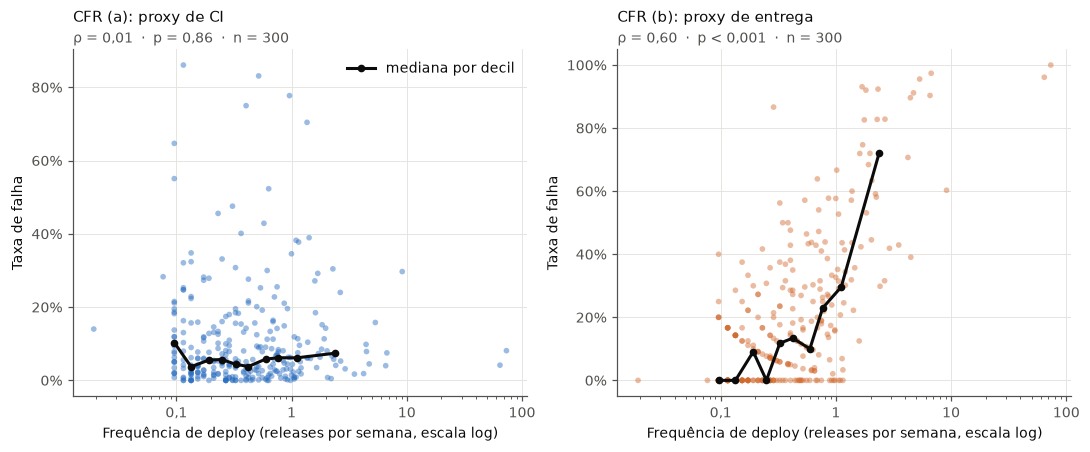

In [4]:
TEXTO, TEXTO_2, GRADE = '#0b0b0b', '#52514e', '#e4e3df'
CORES = ['#256abf', '#d26a2e']
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'font.size': 9,
    'axes.edgecolor': TEXTO_2, 'axes.labelcolor': TEXTO, 'text.color': TEXTO,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
})

def mediana_por_decil(x, y):
    decis = pd.qcut(np.log10(x), 10, duplicates='drop')
    grupos = pd.DataFrame({'x': x, 'y': y}).groupby(decis, observed=True)
    return grupos['x'].median().to_numpy(), grupos['y'].median().to_numpy()


fig, eixos = plt.subplots(1, 2, figsize=(9.8, 4.0), layout='constrained', sharex=True)
for ax, coluna, cor in zip(eixos, ['cfr_a', 'cfr_b'], CORES):
    x, y = df['deploy_freq_release'], df[coluna] * 100
    ax.scatter(x, y, s=14, alpha=0.45, color=cor, edgecolors='none')
    mx, my = mediana_por_decil(x, y)
    ax.plot(mx, my, color=TEXTO, linewidth=2, marker='o', markersize=4, label='mediana por decil')
    linha = spearman.set_index('coluna').loc[coluna]
    p_txt = 'p < 0,001' if linha['p'] < 0.001 else f"p = {linha['p']:.2f}".replace('.', ',')
    ax.set_title(VARIANTES[coluna], loc='left', fontsize=10, pad=18)
    ax.text(0, 1.01, f"ρ = {linha['rho']:.2f}".replace('.', ',') + f"  ·  {p_txt}  ·  n = {int(linha['n'])}",
            transform=ax.transAxes, ha='left', va='bottom', fontsize=9, color=TEXTO_2)
    ax.set_xscale('log')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ',')))
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xlabel('Frequência de deploy (releases por semana, escala log)')
    ax.set_ylabel('Taxa de falha')
eixos[0].legend(loc='upper right', frameon=False)
fig.savefig(FIGURAS / 'rq05_freq_vs_cfr.png')
plt.show()